Shape: (240, 6)
\nData types:\n ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
\nDescriptive statistics:\n        ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.0

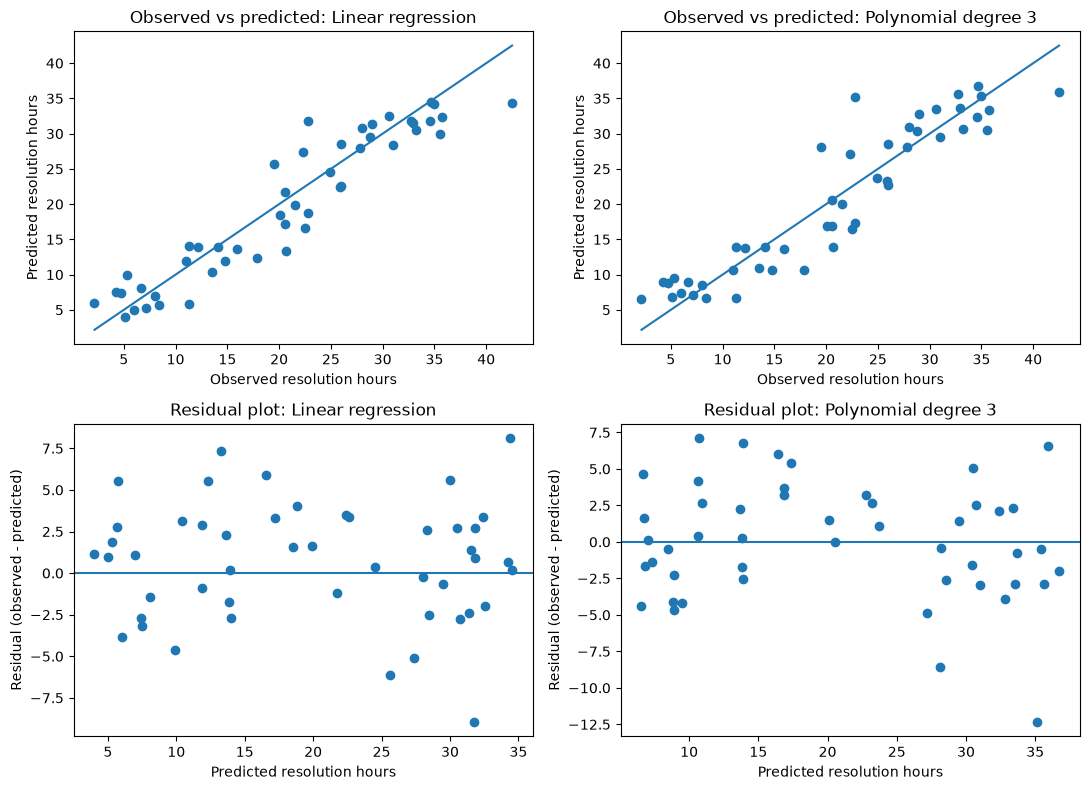

In [3]:
"""
Lab 3: Ticket resolution-time regression.
Run from a terminal in the folder containing lab_ticket_resolution.csv:
    python lab3_solution.py

Feature timing assumption:
- complexity_score and team_experience_years are available when making the estimate.
- lines_changed is excluded because it is measured during/after the fix and can leak future information.
- reopened is excluded because it is only known after a ticket has been resolved/reopened.
- ticket_id is an identifier, not a meaningful predictive feature.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("lab_ticket_resolution.csv")
print("Shape:", df.shape)
print("\\nData types:\\n", df.dtypes)
print("\\nDescriptive statistics:\\n", df.describe(include="all"))
print("\\nMissing values:\\n", df.isna().sum())
print("\\nFirst five rows:\\n", df.head())

y = df["resolution_hours"]
feature_cols = ["complexity_score", "team_experience_years"]
X = df[feature_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Tune alpha only on training folds.
alpha_grid = [0.001, 0.01, 0.1, 1, 10, 100]
ridge_cv, lasso_cv = {}, {}
for alpha in alpha_grid:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))
    ridge_cv[alpha] = -cross_val_score(
        ridge, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
    ).mean()
    lasso_cv[alpha] = -cross_val_score(
        lasso, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
    ).mean()

best_ridge_alpha = min(ridge_cv, key=ridge_cv.get)
best_lasso_alpha = min(lasso_cv, key=lasso_cv.get)

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Polynomial degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(), LinearRegression()
    ),
    "Polynomial degree 3": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(), LinearRegression()
    ),
    f"Ridge (alpha={best_ridge_alpha})": make_pipeline(
        StandardScaler(), Ridge(alpha=best_ridge_alpha)
    ),
    f"Lasso (alpha={best_lasso_alpha})": make_pipeline(
        StandardScaler(), Lasso(alpha=best_lasso_alpha, max_iter=10000)
    ),
}

metrics = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    metrics.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

metrics_df = pd.DataFrame(metrics).sort_values("MAE")
print("\\nTest metrics (lower MAE/RMSE and higher R2 are better):")
print(metrics_df.to_string(index=False))
print("\\nRidge CV MAE by alpha:", ridge_cv)
print("Lasso CV MAE by alpha:", lasso_cv)
print("Selected Ridge alpha:", best_ridge_alpha)
print("Selected Lasso alpha:", best_lasso_alpha)

print("\\nPolynomial degree comparison (5-fold CV MAE on training set):")
for degree in [2, 3]:
    pipe = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(), LinearRegression()
    )
    scores = -cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
    )
    print(f"Degree {degree}: mean MAE={scores.mean():.3f}, std={scores.std():.3f}")

# Diagnostics for two models.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, name in enumerate(["Linear regression", "Polynomial degree 3"]):
    pred = predictions[name]
    axes[0, col].scatter(y_test, pred)
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    axes[0, col].plot([low, high], [low, high])
    axes[0, col].set_xlabel("Observed resolution hours")
    axes[0, col].set_ylabel("Predicted resolution hours")
    axes[0, col].set_title(f"Observed vs predicted: {name}")
    residuals = y_test.to_numpy() - pred
    axes[1, col].scatter(pred, residuals)
    axes[1, col].axhline(0)
    axes[1, col].set_xlabel("Predicted resolution hours")
    axes[1, col].set_ylabel("Residual (observed - predicted)")
    axes[1, col].set_title(f"Residual plot: {name}")
fig.tight_layout()
plt.savefig("lab3_diagnostic_plots.png", dpi=160, bbox_inches="tight")
plt.show()
